# 绘制环形细胞注释树

使用 `ov.pl.celltype_tree()` 在一张图中展示细胞注释层级和标记基因表达。本例使用 [Paul 等人的小鼠骨髓数据](https://scanpy.readthedocs.io/en/stable/generated/scanpy.datasets.paul15.html)，绘制 19 个带注释的细胞簇和九条基因轨道。

## 加载带注释的数据

通过 Scanpy 加载数据。细胞簇标签位于 `adata.obs` 的 `paul15_clusters` 列。

In [1]:
import omicverse as ov
import scanpy as sc

adata = sc.datasets.paul15()
label = "paul15_clusters"
print(f"{adata.n_obs:,} cells, {adata.obs[label].nunique()} clusters")

2,730 cells, 19 clusters


如果只有一列细胞注释，将列名传给 `label` 即可。例如，`ov.pl.celltype_tree(adata, label=label)` 会为每个细胞簇绘制一个叶节点，并标出该簇的细胞占比。

## 添加两级注释

取细胞簇标签的后缀作为亚群，再为每个亚群指定用于展示的大类。如果 `adata.obs` 中已有这些列，可直接传入列名。

In [2]:
family = adata.obs[label].astype(str).str.replace(r"^\d+", "", regex=True)
adata.obs["family"] = family
adata.obs["lineage"] = family.map({
    "Ery": "Ery / Mk", "MEP": "Ery / Mk", "Mk": "Ery / Mk",
    "GMP": "Myeloid", "DC": "Myeloid", "Baso": "Myeloid",
    "Mo": "Myeloid", "Neu": "Myeloid", "Eos": "Myeloid",
    "Lymph": "Lymphoid",
})

## 绘制分类树和基因轨道

按从粗到细的顺序传入层级列。函数按完整注释路径分组，计算各叶节点的细胞占比和所选基因在组内的平均表达。

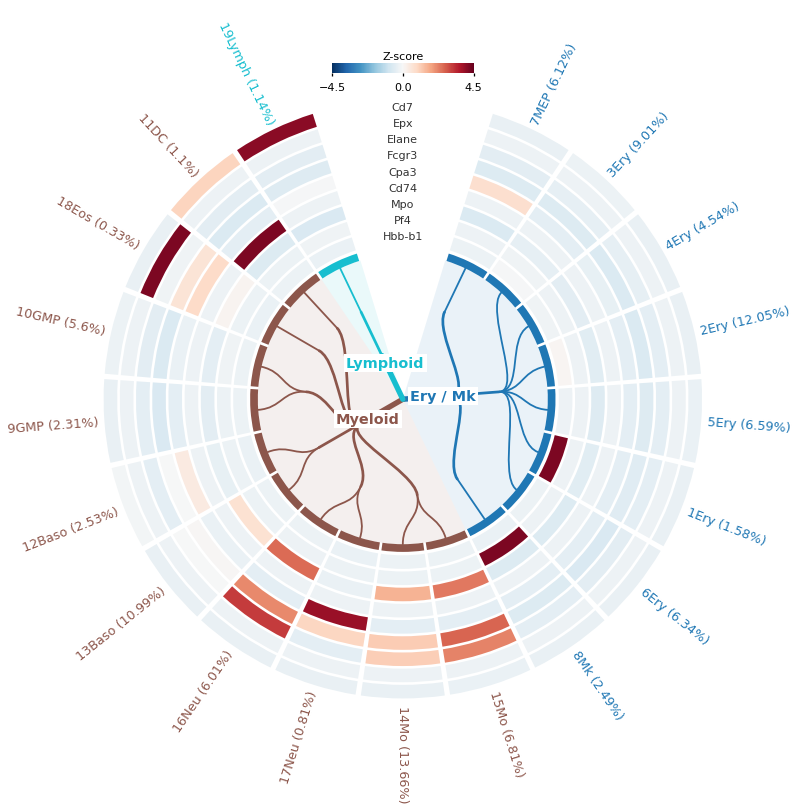

In [3]:
genes = ["Hbb-b1", "Pf4", "Mpo", "Cd74", "Cpa3", "Fcgr3", "Elane", "Epx", "Cd7"]
ax = ov.pl.celltype_tree(
    adata,
    hierarchy=["lineage", "family"],
    label=label,
    tracks=genes,
    standardize=True,
    vmax=4.5,
    figsize=(7.2, 7.2),
    show=False,
)
ax.figure.subplots_adjust(left=0.025, right=0.975, bottom=0.025, top=0.975)
ax.figure

分支使用默认配色区分细胞大类，轨道使用默认的 `RdBu_r` 色图。按 `genes` 中的顺序从内向外阅读轨道。设置 `standardize=True` 后，每个基因在 19 个叶节点上的表达均值会转换为 z 分数。红色表示该簇的均值高于该基因在各簇间的平均值，蓝色表示低于，灰色表示缺失。叶标签中的占比以数据集的 2,730 个细胞为分母。例如，`8Mk` 在第二条轨道上的 `Pf4` 得分最高，`19Lymph` 在最外侧轨道上的 `Cd7` 得分最高。

## 使用自己的数据

- 用 `label` 指定 `adata.obs` 中的叶标签列，用 `hierarchy` 指定更粗的注释列。同一子树的叶节点相邻，同级分支按首次出现的顺序排列。
- 用 `tracks` 指定基因或 `adata.obs` 中的数值列。两者同名时优先使用观测列。基因默认取自 `adata.X`，可设 `layer="log_counts"` 读取该表达层，或设 `use_raw=True` 读取 `adata.raw`。
- 设置 `proportion=False` 隐藏占比。用 `palette` 设置分支颜色，用 `cmap` 或 `vmax` 调整共享色标。
- 如果已有汇总表，可直接传入每个叶节点一行的 DataFrame。此时，`proportion` 可指定取值为 0 到 100 的百分比列。用 `track_markers` 将轨道映射到预先计算的文字标记列。

默认值见[参数参考](../api/reference/omicverse.pl.celltype_tree.rst)。通过返回的坐标轴对象保存图像。

In [4]:
ax.figure.savefig("paul15-celltype-tree.png", dpi=144, bbox_inches="tight", pad_inches=0.06)

## 进阶案例：CIMA 的 73 个细胞亚型

如果每种细胞类型已有一行汇总结果，可以直接传入 DataFrame。本例读取 [CIMA 门户 Cell Atlas 栏目](https://db.cngb.org/trueblood/cima/resource)的五份公开 CSV。scRNA-seq 占比表提供 73 个 L4 亚型名称和各亚型占全部 scRNA-seq 细胞的比例。另四张关联结果表提供 scRNA-seq 和 scATAC-seq 中与年龄、性别相关的统计量。代码按表中公布的细胞类型名称对齐数据。

In [5]:
import pandas as pd

base_url = (
    "https://ftp.cngb.org/pub/SciRAID/trueblood/cima/"
    "CIMA_Resource/Cell_Atlas/CIMA_Cell_Type_L4_"
)
cima = pd.read_csv(base_url + "scRNA_Proportion.csv", index_col="cell_type_l4")
cima["percent"] = 100 * cima["cell_proportion"]

track_files = {
    "RNA age": ("scRNA_Proportion_Age_Related.csv", "correlation"),
    "RNA sex": ("scRNA_Proportion_Sex_Related.csv", "log2FC"),
    "ATAC age": ("scATAC_Proportion_Age_Related.csv", "age_correlation"),
    "ATAC sex": ("scATAC_Proportion_Sex_Related.csv", "log2FC"),
}
for track, (filename, column) in track_files.items():
    summary = pd.read_csv(base_url + filename, index_col=0)
    cima[track] = summary[column]

print(f"{len(cima)} cell subtypes")
print(cima[list(track_files)].count().to_string())

73 cell subtypes
RNA age     71
RNA sex     71
ATAC age    64
ATAC sex    64


根据 L4 名称组织本图的层级。第一层是展示用的大类，第二层取名称中最后一个下划线之前的部分作为亚群。原研究的四级注释见 [Yin 等人](https://doi.org/10.1126/science.adt3130)的图 1E 和表 S1。将 scRNA-seq 占比写入叶标签，以便显示低于 0.01% 的亚型。

In [6]:
display_groups = {
    "HSPC / Mk": r"(HSPC|MK)_.+",
    "Myeloid": r"(.*DC|.*Mono).+|AS_DC",
    "Other T": r"(gdT|MAIT|Immature_T|Proliferative_T).+",
    "CD8 T": r"CD8_.+",
    "CD4 T": r"CD4_.+",
    "NK, NKT, ILC": r"(.*NK|ILC).+",
    "B cells": r"(.*_Bm_|Bn_|Transitional_B_|Plasma).+",
}
for lineage, pattern in display_groups.items():
    cima.loc[cima.index.str.fullmatch(pattern), "lineage"] = lineage

cima["family"] = cima.index.str.rsplit("_", n=1).str[0]
cima["lineage"] = pd.Categorical(cima["lineage"], categories=list(display_groups), ordered=True)
percent = cima["percent"].map(lambda value: "<0.01" if value < 0.01 else f"{value:.2f}")
cima["label"] = cima.index.str.replace("_", " ", regex=False) + " (" + percent + "%)"
cima = cima.sort_values(["lineage", "family", "label"])

### 绘制和解读 CIMA 轨道

图中使用默认分支配色和 `RdBu_r` 色图。从内到外依次为：

| 轨道 | 来源表中的统计量 |
| --- | --- |
| RNA age | 年龄与 scRNA-seq 细胞亚型占比的相关系数。 |
| RNA sex | 两个性别组的 scRNA-seq 细胞亚型占比的 log₂ 倍数变化。 |
| ATAC age | 年龄与 scATAC-seq 细胞亚型占比的相关系数。 |
| ATAC sex | 两个性别组的 scATAC-seq 细胞亚型占比的 log₂ 倍数变化。 |

`standardize=True` 用各轨道自身的均值和标准差计算 z 分数，只使用该轨道中有数值的亚型。红色和蓝色分别表示高于和低于该轨道的均值。原始效应量、方向和 p 值可查来源表。灰色表示缺失或名称未能精确匹配。超出 ±3 的值使用色标两端的颜色。

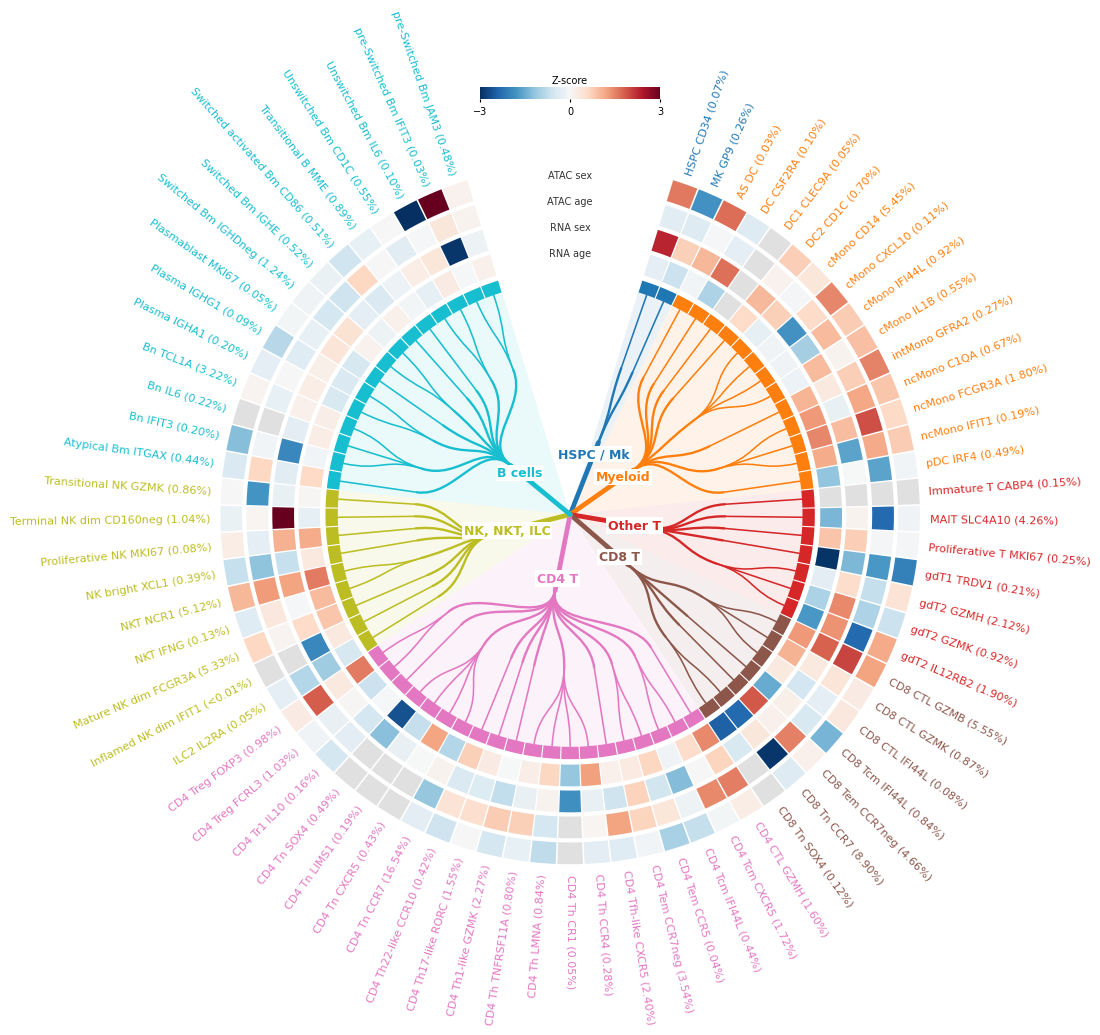

In [7]:
cima_ax = ov.pl.celltype_tree(
    cima,
    hierarchy=["lineage", "family"],
    label="label",
    tracks=list(track_files),
    standardize=True,
    vmax=3,
    figsize=(11, 11),
    show=False,
)
cima_ax.figure.subplots_adjust(left=0.045, right=0.955, bottom=0.045, top=0.955)
cima_ax.figure

## 参考资料

- **示例数据。** Paul F 等。[Transcriptional Heterogeneity and Lineage Commitment in Myeloid Progenitors](https://doi.org/10.1016/j.cell.2015.11.013)。*Cell* 163(7), 1663–1677 (2015)。使用 [`scanpy.datasets.paul15()`](https://scanpy.readthedocs.io/en/stable/generated/scanpy.datasets.paul15.html) 加载。
- **构图参考。** Yin J 等。[Chinese Immune Multi-Omics Atlas](https://doi.org/10.1126/science.adt3130)。*Science* 391(6781), eadt3130 (2026)，图 1E。原图展示四级注释和 73 个末级细胞类型，外圈展示细胞占比及其与年龄、性别的关联。
- **绘图解读。** [微信公众号文章：环形细胞注释树](https://mp.weixin.qq.com/s/F7cgHFmpEAhwhrzAN0NvUA)。